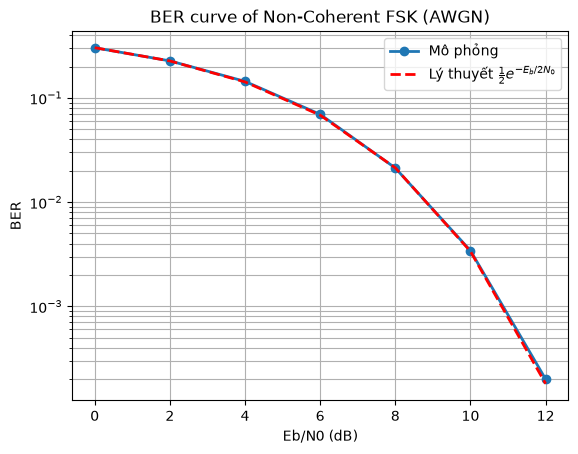

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. Điều chế BFSK ----------
def FSK(bit_seq, A=1, fs=10000, Tb=0.01, f0=100, f1=300):
    samples_per_bit = int(round(Tb * fs))
    t_bit = np.arange(samples_per_bit) / fs
    freqs = np.where(bit_seq == 1, f1, f0)
    return (A * np.cos(2 * np.pi * freqs[:, None] * t_bit)).reshape(-1)

# ---------- 2. Thêm AWGN theo Eb/N0 ----------
def add_awgn(signal, EbN0_dB, A=1, fs=10000, Tb=0.01):
    Eb = A**2 * Tb / 2                      # năng lượng 1 bit của sóng cos biên độ A
    N0 = Eb / 10**(EbN0_dB / 10)
    sigma = np.sqrt(N0 / 2 * fs)            # nhiễu trắng PSD N0/2, lấy mẫu ở tần số fs
    return signal + sigma * np.random.randn(len(signal))

# ---------- 3. Giải điều chế không kết hợp (bộ tách năng lượng I/Q) ----------
def demod_FSK(rx_signal, fs=10000, Tb=0.01, f0=100, f1=300):
    samples_per_bit = int(round(Tb * fs))
    t_bit = np.arange(samples_per_bit) / fs
    chunks = rx_signal.reshape(-1, samples_per_bit)

    def energy(f):
        I = chunks @ np.cos(2 * np.pi * f * t_bit)
        Q = chunks @ np.sin(2 * np.pi * f * t_bit)
        return I**2 + Q**2                  # không phụ thuộc pha sóng mang

    return (energy(f1) > energy(f0)).astype(int)

# ---------- 4. Mô phỏng BER ----------
N_bits = 100000
bit_seq = np.random.randint(0, 2, N_bits)
EbN0_dB = np.arange(0, 13, 2)

tx_signal = FSK(bit_seq)
BER = []
for ebn0 in EbN0_dB:
    rx_bits = demod_FSK(add_awgn(tx_signal, ebn0))
    BER.append(np.mean(bit_seq != rx_bits))

BER_theory = 0.5 * np.exp(-10**(EbN0_dB / 10) / 2)   # BFSK không kết hợp

# ---------- 5. Vẽ BER curve ----------
plt.semilogy(EbN0_dB, BER, 'o-', linewidth=2, label='Mô phỏng')
plt.semilogy(EbN0_dB, BER_theory, 'r--', linewidth=2, label=r'Lý thuyết $\frac{1}{2}e^{-E_b/2N_0}$')
plt.grid(True, which='both')
plt.xlabel("Eb/N0 (dB)")
plt.ylabel("BER")
plt.title("BER curve of Non-Coherent FSK (AWGN)")
plt.legend()
plt.show()

QAM

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from channel import (QAM, QPSK, AWGN, Rayleigh_fading, rayleigh_channel, equalize,
                     set_seed, compute_ber, ber_mqam_rayleigh)

set_seed(42)
N_bits = 1_200_000                  # chia hết cho k = 2, 4, 6, 8
EbN0_dB_range = np.arange(0, 31, 5)
bits_tx = np.random.randint(0, 2, N_bits)

M-QAM Coding (mã Gray: hai điểm kề nhau chỉ khác 1 bit)

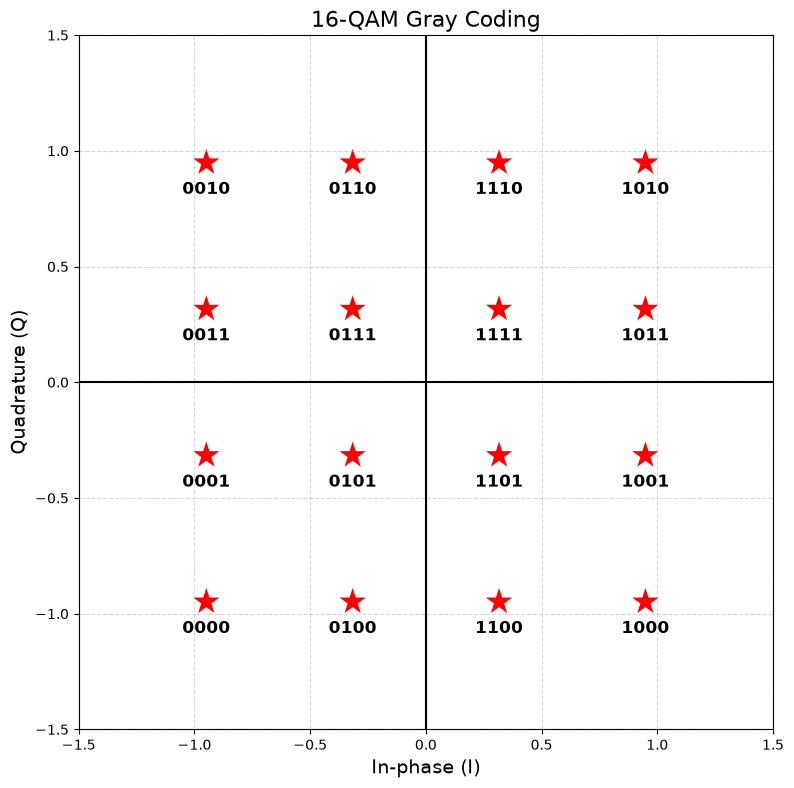

In [3]:
M = 16
qam16 = QAM(M)

fig, ax = plt.subplots(figsize=(8, 8))
ax.axhline(0, color='black', linewidth=1.5)
ax.axvline(0, color='black', linewidth=1.5)

# constellation[idx] mang đúng nhãn Gray = idx
for idx, symbol in enumerate(qam16.constellation):
    ax.scatter(symbol.real, symbol.imag, s=400, c='red', marker='*', edgecolors='none')
    ax.text(symbol.real, symbol.imag - 0.08, np.binary_repr(idx, width=qam16.k),
            ha='center', va='top', fontsize=12, fontweight='bold')

ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xlabel("In-phase (I)", fontsize=14)
ax.set_ylabel("Quadrature (Q)", fontsize=14)
ax.set_title(f"{M}-QAM Gray Coding", fontsize=16)
ax.set_aspect('equal')
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
plt.tight_layout()
plt.show()

BER M-QAM qua kênh Rayleigh (cân bằng ZF)

In [4]:
ber_results = {}
M_list = [4, 16, 64, 256]
for M in M_list:
    qam = QAM(M)
    k = qam.k
    bits_tx_m = bits_tx[:len(bits_tx) - len(bits_tx) % k]
    symbols = qam.bits_to_symbols(bits_tx_m)

    ber_sim = []
    print(f"\n========== Simulating {M}-QAM ==========")
    for EbN0_dB in EbN0_dB_range:
        snr_db = EbN0_dB + 10*np.log10(k)      # Eb/N0 -> Es/N0
        y_eq = Rayleigh_fading(symbols, snr_db, equalizer='zf')   # fading nhanh: mỗi symbol một h
        ber = compute_ber(bits_tx_m, qam.symbols_to_bits(y_eq))
        ber_sim.append(ber)
        print(f"Eb/N0={EbN0_dB:2d} dB -> BER={ber:.6f} | lý thuyết ≈ {ber_mqam_rayleigh(EbN0_dB, M):.6f}")

    ber_results[M] = ber_sim


========== Simulating 4-QAM ==========
Eb/N0= 0 dB -> BER=0.146218 | lý thuyết ≈ 0.146447
Eb/N0= 5 dB -> BER=0.064223 | lý thuyết ≈ 0.064183
Eb/N0=10 dB -> BER=0.023220 | lý thuyết ≈ 0.023269
Eb/N0=15 dB -> BER=0.007644 | lý thuyết ≈ 0.007723
Eb/N0=20 dB -> BER=0.002467 | lý thuyết ≈ 0.002481
Eb/N0=25 dB -> BER=0.000758 | lý thuyết ≈ 0.000789
Eb/N0=30 dB -> BER=0.000253 | lý thuyết ≈ 0.000250

========== Simulating 16-QAM ==========
Eb/N0= 0 dB -> BER=0.196974 | lý thuyết ≈ 0.174554
Eb/N0= 5 dB -> BER=0.103100 | lý thuyết ≈ 0.094756
Eb/N0=10 dB -> BER=0.042307 | lý thuyết ≈ 0.039590
Eb/N0=15 dB -> BER=0.015052 | lý thuyết ≈ 0.013998
Eb/N0=20 dB -> BER=0.004962 | lý thuyết ≈ 0.004601
Eb/N0=25 dB -> BER=0.001597 | lý thuyết ≈ 0.001474
Eb/N0=30 dB -> BER=0.000507 | lý thuyết ≈ 0.000468

========== Simulating 64-QAM ==========
Eb/N0= 0 dB -> BER=0.247196 | lý thuyết ≈ 0.188547
Eb/N0= 5 dB -> BER=0.154408 | lý thuyết ≈ 0.128965
Eb/N0=10 dB -> BER=0.076792 | lý thuyết ≈ 0.067969
Eb/N0=15 dB

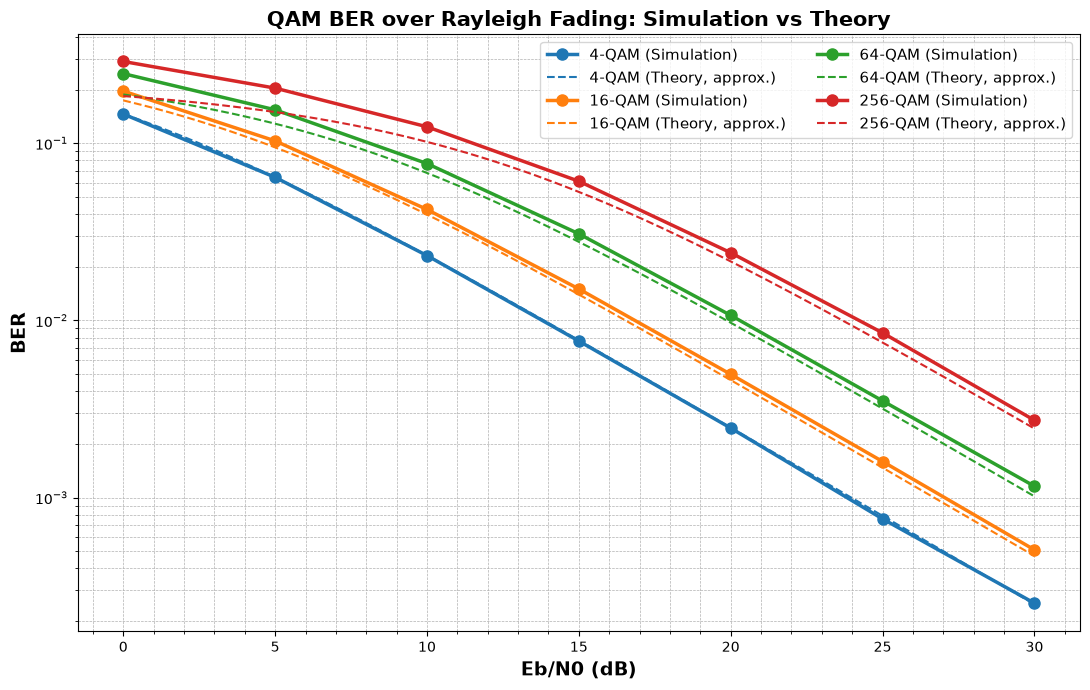

In [5]:
plt.figure(figsize=(11, 7))
EbN0_fine = np.linspace(EbN0_dB_range[0], EbN0_dB_range[-1], 200)

for M in M_list:
    line, = plt.semilogy(EbN0_dB_range, ber_results[M], linestyle='-', linewidth=2.5,
                         marker='o', markersize=8, label=f'{M}-QAM (Simulation)')
    plt.semilogy(EbN0_fine, ber_mqam_rayleigh(EbN0_fine, M), linestyle='--',
                 linewidth=1.5, color=line.get_color(), label=f'{M}-QAM (Theory, approx.)')

plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xlabel("Eb/N0 (dB)", fontsize=14, fontweight='bold')
plt.ylabel("BER", fontsize=14, fontweight='bold')
plt.title("QAM BER over Rayleigh Fading: Simulation vs Theory", fontsize=15, fontweight='bold')
plt.legend(fontsize=11, loc='best', ncol=2)
plt.minorticks_on()
plt.tight_layout()
plt.show()

Chòm sao trước / sau cân bằng: ZF giữ đúng lưới QAM, MMSE làm co chòm sao về gốc

BER sau ZF  : 0.0032
BER sau MMSE: 0.0043


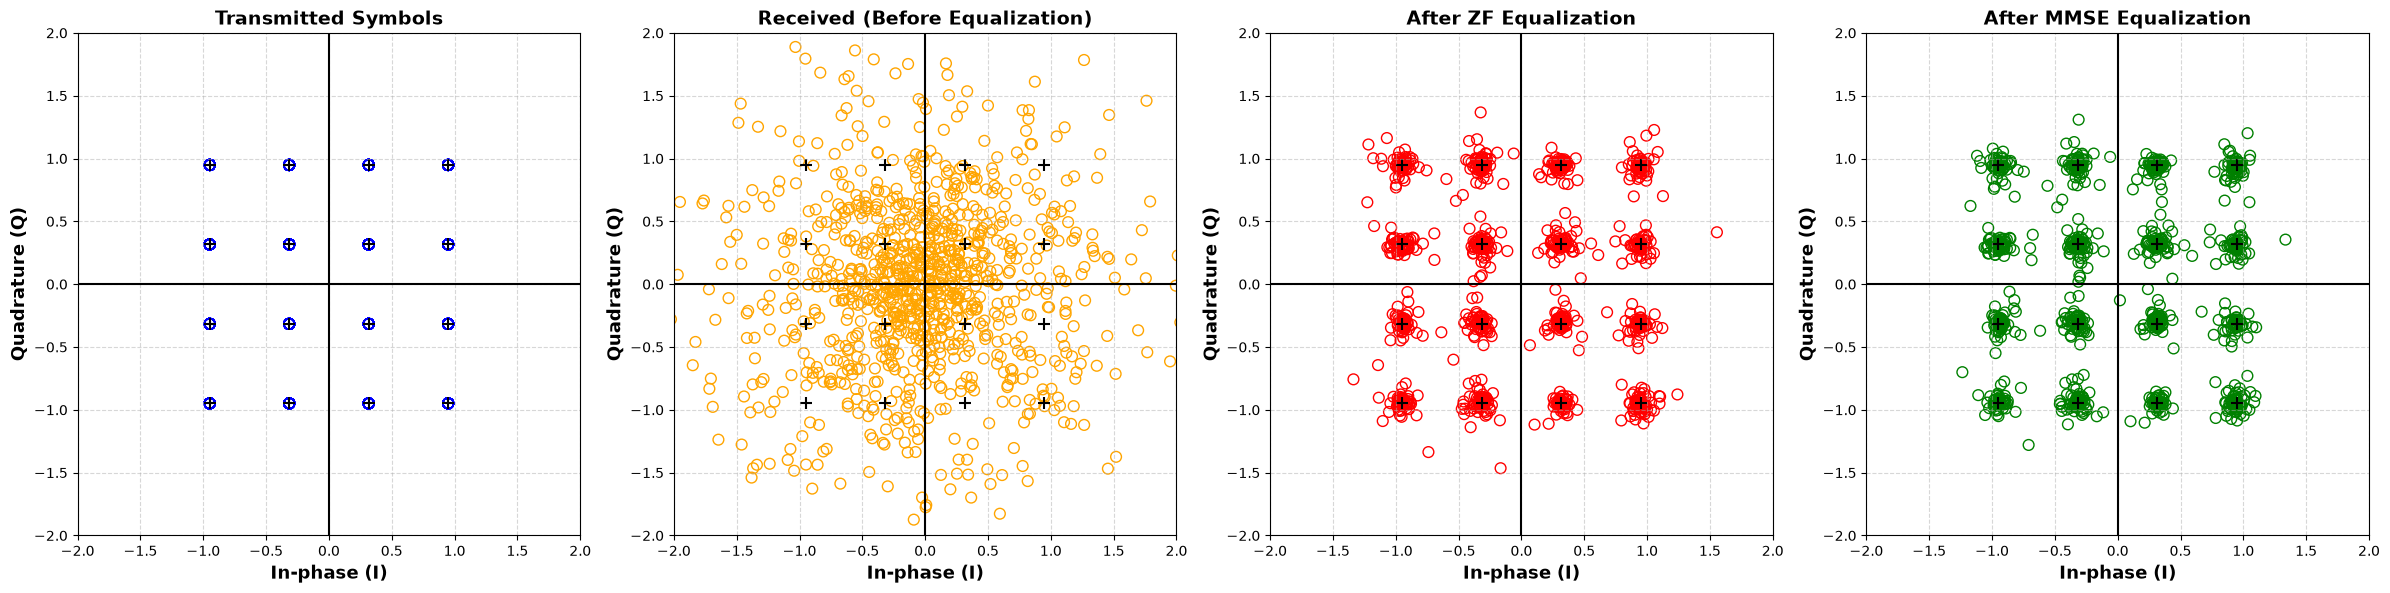

In [6]:
M = 16
qam = QAM(M)
N_symbols = 1000
EbN0_dB = 20

set_seed(42)
bits_demo = np.random.randint(0, 2, N_symbols * qam.k)
symbols_tx = qam.bits_to_symbols(bits_demo)

snr_db = EbN0_dB + 10*np.log10(qam.k)
h = rayleigh_channel(len(symbols_tx))
symbols_noisy, N0 = AWGN(symbols_tx * h, snr_db)
symbols_zf = equalize(symbols_noisy, h, method='zf')
symbols_mmse = equalize(symbols_noisy, h, N0, method='mmse')

for name, s in [('ZF', symbols_zf), ('MMSE', symbols_mmse)]:
    print(f"BER sau {name:4s}: {compute_ber(bits_demo, qam.symbols_to_bits(s)):.4f}")

fig, axes = plt.subplots(1, 4, figsize=(24, 6))
titles = ['Transmitted Symbols', 'Received (Before Equalization)',
          'After ZF Equalization', 'After MMSE Equalization']
colors = ['blue', 'orange', 'red', 'green']
symbol_sets = [symbols_tx, symbols_noisy, symbols_zf, symbols_mmse]

for ax, symbols, color, title in zip(axes, symbol_sets, colors, titles):
    ax.scatter(symbols.real, symbols.imag, s=60, facecolors='none', edgecolors=color, linewidth=1)
    ax.scatter(qam.constellation.real, qam.constellation.imag, s=80, c='black', marker='+')
    ax.axhline(0, color='black', linewidth=1.5)
    ax.axvline(0, color='black', linewidth=1.5)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel("In-phase (I)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Quadrature (Q)", fontsize=13, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_aspect('equal')
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)

plt.tight_layout()
plt.show()

QPSK qua kênh Rician (tuyến vệ tinh GEO), code trong `Modulation.py`

-> Suy hao FSPL: 205.15 dB
-> Tạp âm nền N: -141.61 dBW
--- Mô phỏng (K=10 dB) ---
   SNR:  -3.54 dB | BER Sim: 2.606450e-01
   SNR:  -1.54 dB | BER Sim: 2.109150e-01
   SNR:   0.46 dB | BER Sim: 1.561300e-01
   SNR:   2.46 dB | BER Sim: 1.055900e-01
   SNR:   4.46 dB | BER Sim: 6.194000e-02
   SNR:   6.46 dB | BER Sim: 2.961500e-02
   SNR:   8.46 dB | BER Sim: 1.150000e-02
   SNR:  10.46 dB | BER Sim: 3.695000e-03
   SNR:  12.46 dB | BER Sim: 1.090000e-03
   SNR:  14.46 dB | BER Sim: 2.300000e-04
   SNR:  16.46 dB | BER Sim: 3.000000e-05
   SNR:  18.46 dB | BER Sim: 1.500000e-05
   SNR:  20.46 dB | BER Sim: 0.000000e+00
   SNR:  22.46 dB | BER Sim: 0.000000e+00
   SNR:  24.46 dB | BER Sim: 0.000000e+00
   SNR:  26.46 dB | BER Sim: 0.000000e+00


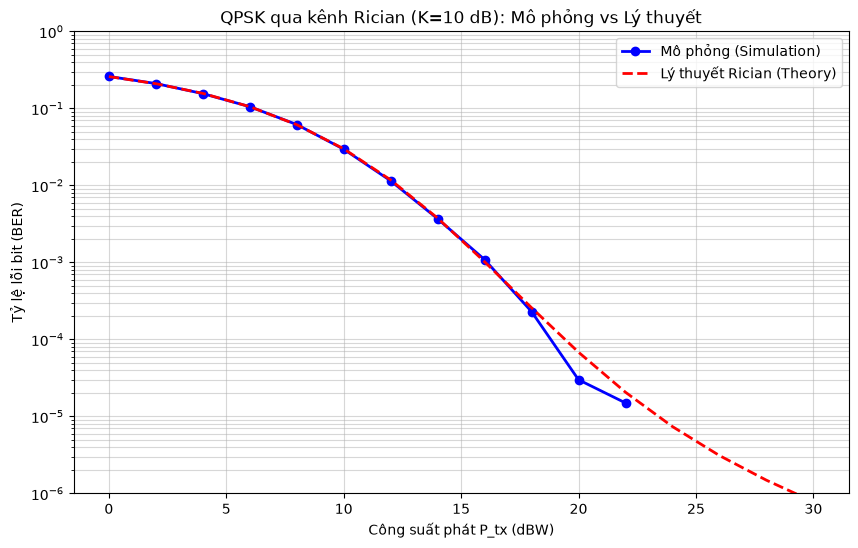

In [7]:
import Modulation
Modulation.main()

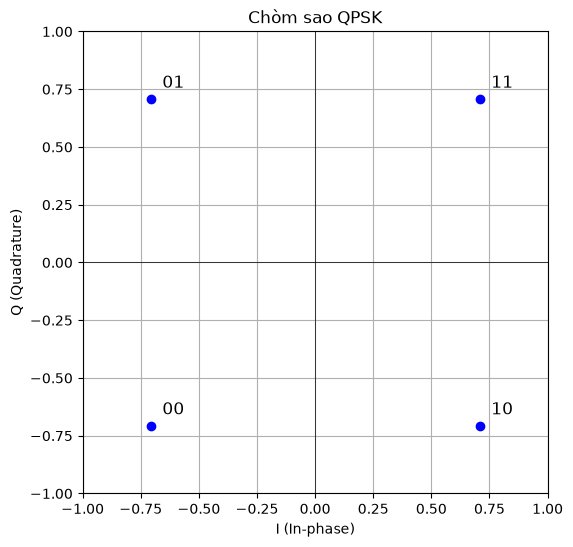

In [8]:
# Chòm sao QPSK lấy trực tiếp từ class QPSK: bit đầu -> dấu I, bit sau -> dấu Q
qpsk = QPSK()
labels = ['00', '01', '10', '11']
points = qpsk.modulate(np.array([[int(b) for b in lb] for lb in labels]))

plt.figure(figsize=(6, 6))
for label, p in zip(labels, points):
    plt.plot(p.real, p.imag, 'bo')
    plt.text(p.real + 0.05, p.imag + 0.05, label, fontsize=12)

plt.axhline(0, color='k', linewidth=0.5)
plt.axvline(0, color='k', linewidth=0.5)
plt.grid(True)
plt.title('Chòm sao QPSK')
plt.xlabel('I (In-phase)')
plt.ylabel('Q (Quadrature)')
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.show()